[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/00_roadmap.ipynb)

# 00 · Roadmap: What Does It Mean for a Machine to *Learn*?

**Part 0 — Foundations** · Notebook 0 of 27

This is the starting point of the whole series. By the end of this notebook you will have:

1. Seen the **one recipe** that almost every ML method in this series follows: **model → loss → optimizer**.
2. Played the role of the optimizer yourself (by dragging sliders), then watched gradient descent do it for you.
3. Seen the four big families of machine learning side by side.
4. A map of all 27 notebooks and how they depend on each other.

No GPU needed. Run the cells top to bottom (`Runtime → Run all` in Colab).

> **How to read these notebooks**
> - 🎚️ marks an **interactive slider**: drag it and watch the plot update.
> - 🎬 marks an **animation**: press ▶ to play it, or scrub frame by frame.
> - 🤔 marks a **question** people commonly ask at that point, with the answer.
> - ✏️ marks an **exercise** for you to try.

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")

Setup complete ✓


---
## 1. Programming vs. learning

In traditional programming, a human writes the rules:

```
data + rules (written by you)  ──►  program  ──►  answers
```

In machine learning, we flip it. We give the computer examples of inputs **and** the answers we want, and it figures out the rules:

```
data + answers (examples)  ──►  learning algorithm  ──►  rules (a "model")
```

The "rules" it learns are usually just **numbers**, called **parameters** (written $\theta$, "theta"). A model with millions of parameters is a function with millions of knobs, and *learning* means turning those knobs until the function's outputs match the answers in the examples.

That's the entire idea. Everything else in this series — from linear regression to GPT — is about three questions:

| Question | Name | Example (apartment rent) |
|---|---|---|
| What shape of function do we use? | **Model** | rent $= \theta_0 + \theta_1 \cdot \text{area}$ |
| How do we measure "wrong"? | **Loss** | average squared error between predicted and real rent |
| How do we turn the knobs to reduce the loss? | **Optimizer** | gradient descent |

---
## 2. A running example: apartment hunting in Atlanta

This example comes straight from CX 4240 (Lecture 2). Suppose you're moving to Atlanta and want to know whether an apartment is reasonably priced. You collect a few listings:

| Living area (ft²) | # Bedrooms | Monthly rent ($) |
|---|---|---|
| 230 | 1 | 900 |
| 506 | 2 | 1800 |
| 433 | 2 | 1500 |
| 190 | 1 | 800 |
| 150 | 1 | **?** |
| 270 | 1.5 | **?** |

The last two rows are apartments you're considering. Can we *learn* a rule from the first four rows that predicts the missing rents?

Four points is too few to see much, so below we generate a larger **synthetic** dataset of 60 Atlanta-style apartments (made-up but realistic numbers) to play with.

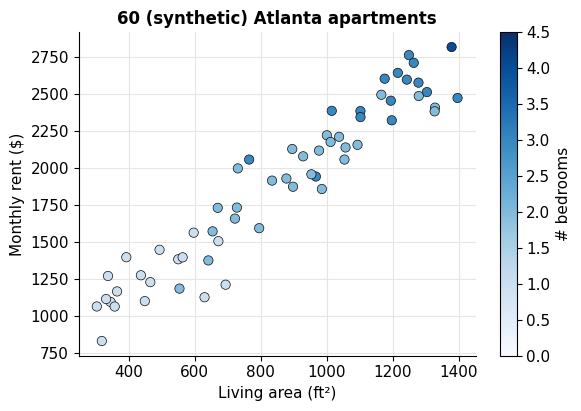

In [2]:
# Synthetic apartments: rent depends on area and bedrooms, plus random "noise"
# (things we can't measure: view, landlord, floor, luck...).
n = 60
area = rng.uniform(300, 1400, n)                              # square feet
bedrooms = np.clip(np.round(area / 450 + rng.normal(0, 0.4, n)), 1, 4)
noise = rng.normal(0, 150, n)                                 # $ of unexplained variation
rent = 500 + 1.4 * area + 100 * bedrooms + noise              # the "true" rule we pretend not to know

fig, ax = plt.subplots()
sc = ax.scatter(area, rent, c=bedrooms, cmap="Blues", vmin=0, vmax=4.5,
                edgecolor=C["ink"], linewidth=0.5, s=45)
plt.colorbar(sc, ax=ax, label="# bedrooms")
ax.set(xlabel="Living area (ft²)", ylabel="Monthly rent ($)",
       title="60 (synthetic) Atlanta apartments")
plt.show()

There's clearly a pattern: bigger apartments cost more. But the points don't sit on a perfect line, because rent also depends on things we didn't record. **Learning** means extracting the pattern while ignoring the noise.

Let's walk through the three ingredients.

---
## 3. Ingredient 1: the model

The simplest model: rent is a straight-line function of area.

$$\widehat{\text{rent}} = \theta_0 + \theta_1 \cdot \text{area}$$

- $\theta_0$ (the **intercept**) is the base rent of a hypothetical 0 ft² apartment.
- $\theta_1$ (the **slope**) is the extra dollars per extra square foot.
- The hat in $\widehat{\text{rent}}$ means "predicted", as opposed to the real rent.

Different values of $(\theta_0, \theta_1)$ give different lines. **Learning = choosing the best $(\theta_0, \theta_1)$.**

---
## 4. Ingredient 2: the loss

To pick the "best" line we need a number that says how wrong a line is. For each apartment $i$, the **residual** is the gap between real and predicted rent:

$$r_i = \text{rent}_i - \widehat{\text{rent}}_i$$

We square each residual (so negatives don't cancel positives, and big misses count extra), then average:

$$\text{MSE}(\theta_0, \theta_1) = \frac{1}{n}\sum_{i=1}^{n} \big(\text{rent}_i - (\theta_0 + \theta_1 \cdot \text{area}_i)\big)^2$$

This is the **mean squared error (MSE)**. Lower is better.

> 🤔 **Question: Why *squared* error? Why not just the absolute value of the error?**
>
> Both are legitimate choices, and they lead to different models. Squared error has two big advantages: it is smooth (easy to differentiate, which matters for ingredient 3), and it falls out naturally if you assume the noise is **Gaussian**. That's derived properly in notebook **02**. Absolute error is more robust to outliers; notebook 02 shows that side by side too.

### 🎚️ You be the optimizer

Drag the two sliders to find the line with the lowest MSE. The red vertical segments are the residuals. Can you get the MSE under 26,000?

In [3]:
def plot_line_fit(theta0=200.0, theta1=1.0):
    pred = theta0 + theta1 * area
    mse = np.mean((rent - pred) ** 2)
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.vlines(area, pred, rent, color=C["red"], alpha=0.5, linewidth=1.2, label="residuals")
    ax.scatter(area, rent, color=C["blue"], edgecolor=C["ink"], linewidth=0.5, s=35, zorder=3, label="apartments")
    xs = np.array([250, 1450])
    ax.plot(xs, theta0 + theta1 * xs, color=C["ink"], linewidth=2.5, label="your line")
    ax.set(xlim=(250, 1450), ylim=(0, 3500), xlabel="Living area (ft²)", ylabel="Monthly rent ($)")
    ax.set_title(f"rent = {theta0:.0f} + {theta1:.2f}·area      MSE = {mse:,.0f}")
    ax.legend(loc="upper left")
    plt.show()

interact(plot_line_fit,
         theta0=FloatSlider(value=200, min=-500, max=1500, step=10, description="θ₀ (base $)"),
         theta1=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.02, description="θ₁ ($/ft²)"));

You probably noticed a strategy: nudge a slider, check whether the MSE went up or down, and keep going in the direction that lowers it. **That is exactly what gradient descent does**, except it computes the best direction with calculus instead of trial and error.

Let's see the whole **loss landscape**: the MSE for *every* combination of $(\theta_0, \theta_1)$. Each point on this map is one possible line.

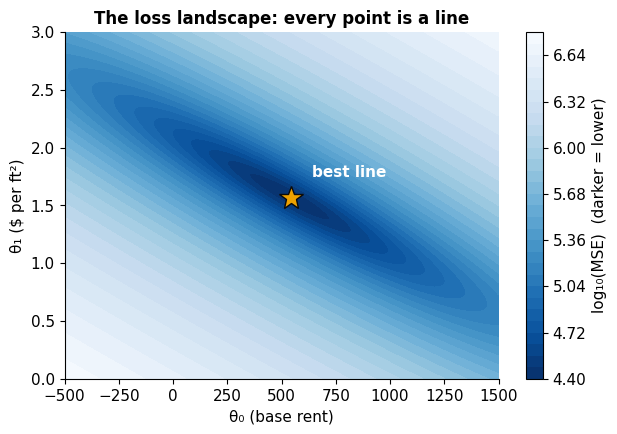

Best on this grid: θ0 ≈ 545, θ1 ≈ 1.57, MSE ≈ 25,863


In [4]:
t0 = np.linspace(-500, 1500, 200)
t1 = np.linspace(0.0, 3.0, 200)
T0, T1 = np.meshgrid(t0, t1)
# MSE for every (θ0, θ1) on the grid at once (broadcasting: grid × apartments)
L = np.mean((rent[None, None, :] - (T0[..., None] + T1[..., None] * area[None, None, :])) ** 2, axis=-1)

best = np.unravel_index(L.argmin(), L.shape)
fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contourf(T0, T1, np.log10(L), levels=30, cmap="Blues_r")
plt.colorbar(cs, ax=ax, label="log₁₀(MSE)  (darker = lower)")
ax.plot(T0[best], T1[best], marker="*", color=C["yellow"], markersize=18, markeredgecolor=C["ink"])
ax.annotate("best line", (T0[best], T1[best]), xytext=(15, 15), textcoords="offset points", color="white", weight="bold")
ax.set(xlabel="θ₀ (base rent)", ylabel="θ₁ ($ per ft²)", title="The loss landscape: every point is a line")
ax.grid(False)
plt.show()
print(f"Best on this grid: θ0 ≈ {T0[best]:.0f}, θ1 ≈ {T1[best]:.2f}, MSE ≈ {L[best]:,.0f}")

The landscape is a long, narrow **valley**. Many combinations are *almost* as good, because you can trade a higher base rent for a lower per-ft² price and get similar lines. That stretched shape makes optimization harder, and notebook **03** shows exactly why (and how to fix it).

> 🤔 **Question: Why plot log(MSE) instead of MSE?**
>
> MSE ranges from about 20,000 near the best line to millions far away. On a linear color scale everything except the far corners would look the same color. The log compresses that range so you can see the shape of the valley.

---
## 5. Ingredient 3: the optimizer (gradient descent)

Here's the idea in one sentence: **at your current $\theta$, find the direction in which the loss goes *down* most steeply, take a small step that way, repeat.**

That "steepest" direction is the negative **gradient**, $-\nabla_\theta \text{MSE}$. Notebook **04** builds gradients from scratch, so for now just trust the formula. For our model:

$$\frac{\partial\,\text{MSE}}{\partial \theta_0} = -\frac{2}{n}\sum_i r_i, \qquad \frac{\partial\,\text{MSE}}{\partial \theta_1} = -\frac{2}{n}\sum_i r_i \cdot \text{area}_i$$

and each step is

$$\theta \leftarrow \theta - \eta \, \nabla_\theta \text{MSE}$$

where $\eta$ ("eta") is the **learning rate**, the step size.

One practical trick first: we **standardize** the area (subtract its mean, divide by its standard deviation). That turns the narrow valley above into a round bowl, so gradient descent converges in a few dozen steps instead of thousands. Notebook 03 explains why this works.

In [5]:
# Standardize the feature: z = (area - mean) / std
mu_a, sd_a = area.mean(), area.std()
z = (area - mu_a) / sd_a

def gradient_descent(z, y, lr=0.1, steps=40):
    theta = np.array([0.0, 0.0])                   # start with a flat line at $0
    history = [theta.copy()]
    for _ in range(steps):
        pred = theta[0] + theta[1] * z
        r = y - pred                                # residuals
        grad = np.array([-2 * r.mean(), -2 * (r * z).mean()])
        theta = theta - lr * grad                   # the gradient-descent step
        history.append(theta.copy())
    return np.array(history)

hist = gradient_descent(z, rent)
losses = [np.mean((rent - (a + b * z)) ** 2) for a, b in hist]
print(f"Start: MSE = {losses[0]:,.0f}")
print(f"After {len(hist)-1} steps: MSE = {losses[-1]:,.0f}")

# Convert back to "rent = θ0 + θ1·area" in original units so it's interpretable
th1 = hist[-1, 1] / sd_a
th0 = hist[-1, 0] - th1 * mu_a
print(f"Learned rule: rent ≈ {th0:.0f} + {th1:.2f} · area")

Start: MSE = 3,848,583
After 40 steps: MSE = 25,854
Learned rule: rent ≈ 536 + 1.58 · area


### 🎬 Watch gradient descent learn

Left: the line after each step. Right: the loss dropping. Press ▶.

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8), dpi=80)
ax1.scatter(area, rent, color=C["blue"], edgecolor=C["ink"], linewidth=0.4, s=25)
xs = np.linspace(250, 1450, 2)
line, = ax1.plot([], [], color=C["ink"], linewidth=2.5)
title = ax1.set_title("")
ax1.set(xlim=(250, 1450), ylim=(-200, 3500), xlabel="Living area (ft²)", ylabel="Rent ($)")
ax2.set(xlim=(0, len(losses) - 1), ylim=(1e4, max(losses) * 1.3), yscale="log",
        xlabel="step", ylabel="MSE (log scale)", title="Loss")
loss_line, = ax2.plot([], [], color=C["orange"])
dot, = ax2.plot([], [], "o", color=C["orange"], markersize=8)
fig.tight_layout()

def frame(k):
    a, b = hist[k]
    line.set_data(xs, a + b * (xs - mu_a) / sd_a)
    title.set_text(f"step {k}: MSE = {losses[k]:,.0f}")
    loss_line.set_data(range(k + 1), losses[:k + 1])
    dot.set_data([k], [losses[k]])
    return line, loss_line, dot

show_anim(animation.FuncAnimation(fig, frame, frames=len(hist), interval=150))

That is machine learning, start to finish: a **model** (a line), a **loss** (MSE), and an **optimizer** (gradient descent) that turns the knobs automatically.

Now we can answer the question from the start: what should the two apartments you were considering cost? Let's use both features (area **and** bedrooms) this time, solving for the best $\theta$ exactly with linear algebra (the "normal equation", derived in notebook **01**).

In [7]:
# Design matrix X: a column of 1s (for θ0), then area, then bedrooms
X = np.column_stack([np.ones(n), area, bedrooms])
theta = np.linalg.solve(X.T @ X, X.T @ rent)       # normal equation: (XᵀX) θ = Xᵀy
print(f"rent ≈ {theta[0]:.0f} + {theta[1]:.2f}·area + {theta[2]:.0f}·bedrooms\n")

for a, b in [(150, 1), (270, 1.5)]:
    print(f"  {a} ft², {b} bed  →  predicted rent ≈ ${theta @ [1, a, b]:,.0f}")

rent ≈ 493 + 1.25·area + 162·bedrooms

  150 ft², 1 bed  →  predicted rent ≈ $842
  270 ft², 1.5 bed  →  predicted rent ≈ $1,074


> 🤔 **Question: If there's an exact formula, why bother with gradient descent at all?**
>
> Two reasons. (1) The exact formula only exists for a few simple models like linear regression. For logistic regression, neural networks and GPT there is no closed-form answer, so iterative methods like gradient descent are the *only* option. (2) Even when a formula exists, it requires solving a $d \times d$ system, which becomes slow for millions of features. Gradient descent scales to billions of parameters. CX 4240 Lecture 4 makes exactly this point.

> 🤔 **Question: We generated the data with `rent = 500 + 1.4·area + 100·bedrooms`. Why didn't we recover exactly those numbers?**
>
> Because of the noise. With 60 noisy apartments, the best-fitting $\theta$ is close to the true one but not identical. With more data the estimates get closer. This gap between "the truth" and "what the data supports" is a central theme of **statistics**, explored in notebooks 02 and 06.

---
## 6. The real goal: doing well on *new* data

Fitting the training data is not actually the goal. The goal is to predict apartments **we haven't seen**. A model that memorizes its training data can fail badly on new data. This is called **overfitting**.

### 🎚️ Overfitting in action

Below we fit polynomials of increasing degree to just **12** apartments (blue), then test on 48 *other* apartments (orange). Drag the degree up and watch: training error keeps falling, but past a point the curve starts wiggling to hit every training point, and test error explodes.

In [8]:
idx = rng.permutation(n)
tr, te = idx[:12], idx[12:]
zs = (area - area[tr].mean()) / area[tr].std()      # standardize using training data only

def fit_poly(degree):
    coefs = np.polyfit(zs[tr], rent[tr], degree)
    mse_tr = np.mean((np.polyval(coefs, zs[tr]) - rent[tr]) ** 2)
    mse_te = np.mean((np.polyval(coefs, zs[te]) - rent[te]) ** 2)
    return coefs, mse_tr, mse_te

def plot_poly(degree=1):
    coefs, mse_tr, mse_te = fit_poly(degree)
    grid = np.linspace(zs.min(), zs.max(), 400)
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.scatter(area[te], rent[te], color=C["orange"], s=22, alpha=0.6, label="test (unseen)")
    ax.scatter(area[tr], rent[tr], color=C["blue"], edgecolor=C["ink"], s=55, zorder=3, label="train (12 pts)")
    ax.plot(grid * area[tr].std() + area[tr].mean(), np.polyval(coefs, grid), color=C["ink"], label=f"degree {degree}")
    ax.set(ylim=(0, 3500), xlabel="Living area (ft²)", ylabel="Rent ($)")
    ax.set_title(f"train MSE = {mse_tr:,.0f}    test MSE = {mse_te:,.0f}")
    ax.legend(loc="upper left")
    plt.show()

interact(plot_poly, degree=IntSlider(value=1, min=1, max=10, description="degree"));

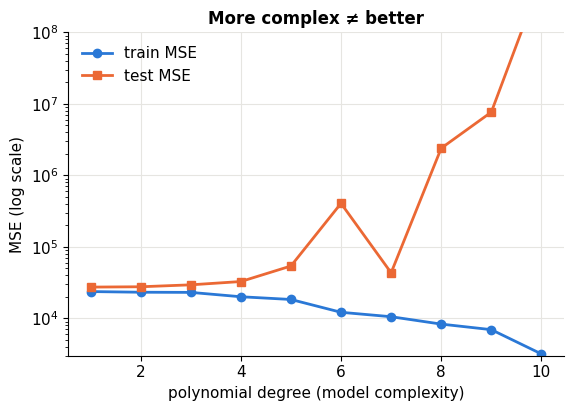

In [9]:
degrees = range(1, 11)
results = np.array([fit_poly(d)[1:] for d in degrees])
fig, ax = plt.subplots()
ax.plot(degrees, results[:, 0], "o-", label="train MSE")
ax.plot(degrees, results[:, 1], "s-", label="test MSE")
ax.set(yscale="log", ylim=(3e3, 1e8), xlabel="polynomial degree (model complexity)", ylabel="MSE (log scale)",
       title="More complex ≠ better")
ax.legend()
plt.show()

This U-shaped test curve is the **bias–variance tradeoff**. Too simple a model misses the pattern (underfitting), too complex a model memorizes noise (overfitting). Notebook **06** is devoted to it, along with cross-validation, the standard tool for picking the right complexity.

> 🤔 **Question: Then why do huge neural networks with billions of parameters not overfit?**
>
> Great question, and an active research area. Part of the answer: they are trained on enormous datasets, use regularization, and stochastic gradient descent has an implicit preference for "simple" solutions. There is also a phenomenon called **double descent**, where test error goes down again for very over-parameterized models. We'll revisit this in Parts 3 and 5.

---
## 7. The four families of machine learning

All of ML splits into a few families, depending on **what kind of answers (labels) you have**.

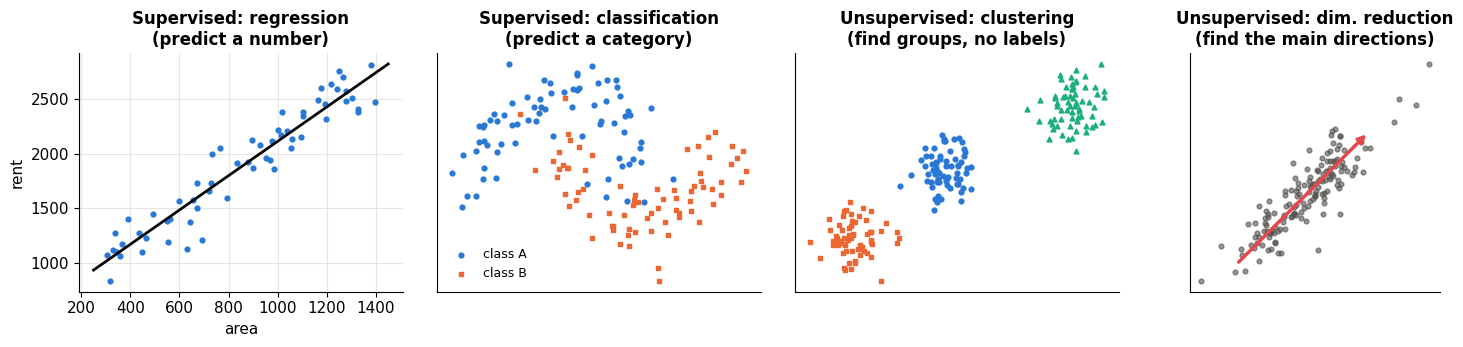

In [10]:
from sklearn.datasets import make_blobs, make_moons

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))

# Supervised — regression: predict a number
ax = axes[0]
ax.scatter(area, rent, s=12, color=C["blue"])
ax.plot(xs, th0 + th1 * xs, color=C["ink"])
ax.set_title("Supervised: regression\n(predict a number)")
ax.set(xlabel="area", ylabel="rent")

# Supervised — classification: predict a category
ax = axes[1]
Xm, ym = make_moons(150, noise=0.2, random_state=0)
ax.scatter(*Xm[ym == 0].T, s=12, color=C["blue"], label="class A")
ax.scatter(*Xm[ym == 1].T, s=12, color=C["orange"], marker="s", label="class B")
ax.set_title("Supervised: classification\n(predict a category)")
ax.legend(loc="lower left", fontsize=9)

# Unsupervised — clustering: find groups without labels
ax = axes[2]
Xb, yb = make_blobs(200, centers=3, cluster_std=0.9, random_state=3)
for k, (col, mk) in enumerate(zip([C["blue"], C["orange"], C["aqua"]], ["o", "s", "^"])):
    ax.scatter(*Xb[yb == k].T, s=12, color=col, marker=mk)
ax.set_title("Unsupervised: clustering\n(find groups, no labels)")

# Unsupervised — dimensionality reduction: find the main direction
ax = axes[3]
Xc = rng.multivariate_normal([0, 0], [[3, 2.6], [2.6, 3]], 150)
ax.scatter(*Xc.T, s=12, color=C["muted"], alpha=0.6)
ax.annotate("", xy=(3.3, 3.3), xytext=(-3.3, -3.3), arrowprops=dict(arrowstyle="->", color=C["red"], lw=2.5))
ax.set_title("Unsupervised: dim. reduction\n(find the main directions)")
ax.set_aspect("equal")

for ax in axes[1:]:
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plt.show()

| Family | What you're given | What you learn | Examples in this series |
|---|---|---|---|
| **Supervised** | inputs **and** correct answers | a function input → answer | linear/logistic regression, SVM, trees, neural nets (05–13, 19–22) |
| **Unsupervised** | inputs only | structure: groups, directions, densities | k-means, GMM, PCA, recommenders, anomaly detection (14–18) |
| **Self-supervised** | inputs only, but you *invent* labels from the data itself | representations | VAE, contrastive learning, GPT (predict the next word!) (23–25) |
| **Reinforcement** | an environment that gives **rewards** | a policy: which action to take | RLHF / post-training of LLMs (26) |

> 🤔 **Question: Is GPT supervised or unsupervised?**
>
> Both, depending on how you look at it, which is why the term **self-supervised** exists. The training data is raw text with no human labels (unsupervised), but the model is trained exactly like a supervised classifier whose "label" is the next word, taken from the text itself. Then post-training adds supervised fine-tuning and reinforcement learning on top (notebook 26).

---
## 8. One recipe for (almost) everything

CX 4240 frames every algorithm with the same three steps. Here's how that plays out across the series. Notice how the same few losses and optimizers keep reappearing:

| Notebook | 1. Probabilistic model | 2. Loss (from MLE or MAP) | 3. Optimizer |
|---|---|---|---|
| 05 Linear regression | Gaussian noise + linear function | mean squared error | closed form **or** gradient descent |
| 07 Ridge / Lasso | + Gaussian / Laplace prior on θ | MSE + λ‖θ‖² / λ‖θ‖₁ | closed form / coordinate descent |
| 08 Logistic regression | Bernoulli + linear function | binary cross-entropy | gradient descent |
| 09 Naive Bayes | class prior × per-feature likelihoods | negative log-likelihood | closed form (counting!) |
| 15 Gaussian mixtures | mixture of Gaussians + hidden cluster label | negative log-likelihood | EM algorithm |
| 16 PCA (probabilistic) | Gaussian latent variable | negative log-likelihood | eigendecomposition |
| 19 Neural networks | Gaussian / Bernoulli / Categorical + neural net | MSE / cross-entropy | SGD + backprop |
| 23 VAE | deep latent variable model | ELBO (a bound on the likelihood) | SGD + reparameterization trick |
| 25 GPT | Categorical over next token + transformer | cross-entropy | Adam (a fancier SGD) |
| 26 RLHF / DPO | policy + reward / preference model | reward + KL penalty / preference loss | policy gradient / SGD |

The Part 0 notebooks give you the tools that fill every column of this table:

| Notebook | What it gives you | Where it shows up in the apartment example |
|---|---|---|
| **01 Linear algebra** | vectors, matrices, eigenvectors, SVD | the model $\hat y = X\theta$ and the exact solution $(X^\top X)\theta = X^\top y$ |
| **02 Probability & statistics** | distributions, MLE, MAP | *why* the loss is squared error (Gaussian noise) |
| **03 Optimization** | gradient descent, SGD, Adam, convexity | *how* we found the best line, and why standardizing helped |
| **04 Gradients & backprop** | derivatives, chain rule, autograd | *how* the gradient is computed automatically for any model |

---
## 9. Map of the series

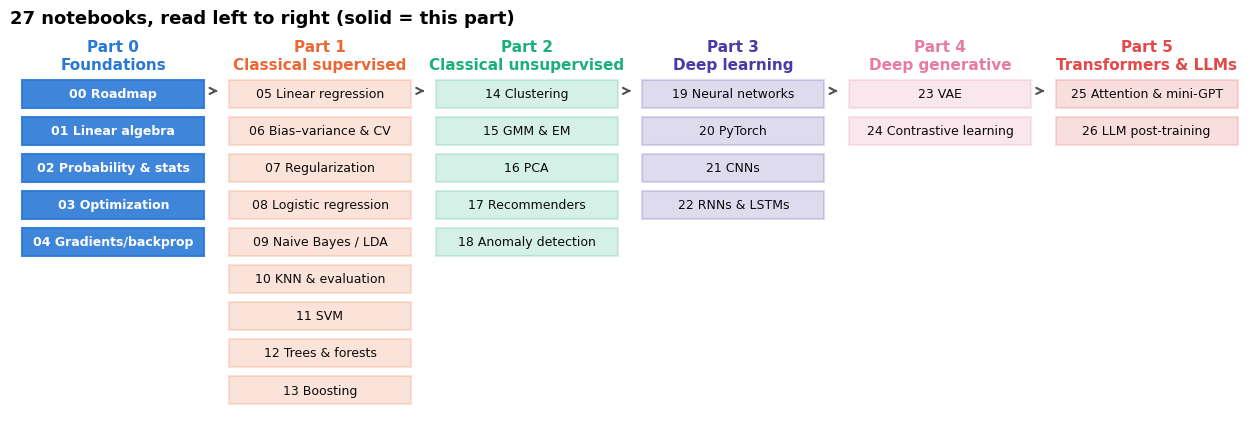

In [11]:
parts = [
    ("Part 0\nFoundations", C["blue"], ["00 Roadmap", "01 Linear algebra", "02 Probability & stats", "03 Optimization", "04 Gradients/backprop"]),
    ("Part 1\nClassical supervised", C["orange"], ["05 Linear regression", "06 Bias–variance & CV", "07 Regularization", "08 Logistic regression",
                                                    "09 Naive Bayes / LDA", "10 KNN & evaluation", "11 SVM", "12 Trees & forests", "13 Boosting"]),
    ("Part 2\nClassical unsupervised", C["aqua"], ["14 Clustering", "15 GMM & EM", "16 PCA", "17 Recommenders", "18 Anomaly detection"]),
    ("Part 3\nDeep learning", C["violet"], ["19 Neural networks", "20 PyTorch", "21 CNNs", "22 RNNs & LSTMs"]),
    ("Part 4\nDeep generative", C["magenta"], ["23 VAE", "24 Contrastive learning"]),
    ("Part 5\nTransformers & LLMs", C["red"], ["25 Attention & mini-GPT", "26 LLM post-training"]),
]
fig, ax = plt.subplots(figsize=(16, 5.2))
ax.set_xlim(0, len(parts)); ax.set_ylim(-9.6, 1.2); ax.axis("off")
for j, (name, col, items) in enumerate(parts):
    ax.text(j + 0.5, 0.55, name, ha="center", va="center", fontsize=11, weight="bold", color=col)
    for i, it in enumerate(items):
        ax.add_patch(plt.Rectangle((j + 0.06, -i - 0.85), 0.88, 0.75, facecolor=col,
                                   alpha=0.9 if j == 0 else 0.18, edgecolor=col, linewidth=1.5))
        ax.text(j + 0.5, -i - 0.475, it, ha="center", va="center", fontsize=9,
                color="white" if j == 0 else C["ink"], weight="bold" if j == 0 else "normal")
    if j < len(parts) - 1:
        ax.annotate("", xy=(j + 1.02, -0.4), xytext=(j + 0.98, -0.4),
                    arrowprops=dict(arrowstyle="->", color=C["muted"], lw=1.5))
ax.set_title("27 notebooks, read left to right (solid = this part)", loc="left", fontsize=13)
plt.show()

**Key connections** (you'll see "remember notebook X?" a lot):

- **01 → 16, 17:** eigenvectors and the SVD *are* PCA and matrix-factorization recommenders.
- **02 → everywhere:** every loss in the table above comes from a likelihood.
- **03 → 11:** Lagrange multipliers and KKT conditions are how SVMs are derived.
- **04 → 19 → 21, 22, 25:** the autograd engine you build in 04 is what PyTorch does inside every deep model.
- **15 + 16 → 23:** EM's lower bound and probabilistic PCA become the VAE's ELBO.
- **22 → 25:** attention was invented to fix the RNN bottleneck.

---
## 10. Summary

- **Learning = choosing parameters $\theta$** so a model's outputs match example answers.
- Every method is a **model** (function shape), a **loss** (how wrong), and an **optimizer** (how to reduce the loss).
- **Gradient descent** repeatedly steps in the direction that decreases the loss fastest.
- The true goal is **generalization** to unseen data; too much flexibility leads to **overfitting**.
- ML families differ by what supervision you have: answers (supervised), none (unsupervised), self-made labels (self-supervised), or rewards (RL).

### ✏️ Exercises

1. In the "you be the optimizer" slider, find the best line you can and write down $\theta_0, \theta_1$. Compare with what gradient descent learned. How close were you?
2. Change `lr=0.1` in `gradient_descent` to `0.5`, `0.9`, then `1.1`. What happens? (Notebook 03 explains the threshold.)
3. In the overfitting experiment, change the training set size from 12 to 40 (`idx[:40]`). Does the degree-10 polynomial still overfit as badly? Why?
4. Which family would each of these be? (a) Grouping Delta flights by delay pattern without labels. (b) Predicting whether a flight will be delayed > 15 min. (c) A model that learns to play chess by playing itself.

### References

- CX 4240 (Bo Dai), Lectures 1–2 and 6: the apartment-hunting example and the "model → loss → optimizer" pipeline.
- ISYE 4600 (Moghaddam), W1: Methods & Applications of ML.
- Andrej Karpathy, *Neural Networks: Zero to Hero*, for the build-it-from-scratch spirit of this series.

**Next → [01 · Linear Algebra for ML](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/01_linear_algebra.ipynb)**